# Exploratory Data Analysis

## Setup

Imports and read the csv file

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use("seaborn-v0_8")

# Load the dataset
building_consumption = pd.read_csv("../data/raw/2016_Building_Energy_Benchmarking.csv")

## Scope and target

**Goal:** predict the energy consumption of **non-residential** buildings.

- **Target:** `SiteEnergyUse(kBtu)` (total energy consumed on site).
- **Scope:** the file mixes multifamily housing (~1,700 rows) with non-residential buildings (~1,670 rows), so we have to filter.
- **Leakage:** many columns are computed from the energy bills (EUI, electricity, gas, steam, GHG). They cannot be used as features: for a building with no consumption data yet, we would not have them.

In [2]:
# Display the first few rows of the dataset
building_consumption.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [3]:
building_consumption.info()

<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   str    
 3   PrimaryPropertyType              3376 non-null   str    
 4   PropertyName                     3376 non-null   str    
 5   Address                          3376 non-null   str    
 6   City                             3376 non-null   str    
 7   State                            3376 non-null   str    
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   str    
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   str    
 12  Latitude                       

In [4]:
building_consumption.describe()

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,...,SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),Comments,TotalGHGEmissions,GHGEmissionsIntensity
count,3376.000000,3376.0,3360.000000,3376.000000,3376.000000,3376.000000,3376.000000,3368.000000,3376.000000,3.376000e+03,...,3.371000e+03,3.370000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,0.0,3367.000000,3367.000000
mean,21208.991114,2016.0,98116.949107,4.439277,47.624033,-122.334795,1968.573164,1.106888,4.709123,9.483354e+04,...,5.403667e+06,5.276726e+06,2.745959e+05,1.086639e+06,3.707612e+06,1.368505e+04,1.368505e+06,NaN,119.723971,1.175916
std,12223.757015,0.0,18.615205,2.120625,0.047758,0.027203,33.088156,2.108402,5.494465,2.188376e+05,...,2.161063e+07,1.593879e+07,3.912173e+06,4.352478e+06,1.485066e+07,6.709781e+04,6.709781e+06,NaN,538.832227,1.821452
min,1.000000,2016.0,98006.000000,1.000000,47.499170,-122.414250,1900.000000,0.000000,0.000000,1.128500e+04,...,0.000000e+00,0.000000e+00,0.000000e+00,-3.382680e+04,-1.154170e+05,0.000000e+00,0.000000e+00,NaN,-0.800000,-0.020000
25%,19990.750000,2016.0,98105.000000,3.000000,47.599860,-122.350662,1948.000000,1.000000,2.000000,2.848700e+04,...,9.251286e+05,9.701822e+05,0.000000e+00,1.874229e+05,6.394870e+05,0.000000e+00,0.000000e+00,NaN,9.495000,0.210000
50%,23112.000000,2016.0,98115.000000,4.000000,47.618675,-122.332495,1975.000000,1.000000,4.000000,4.417500e+04,...,1.803753e+06,1.904452e+06,0.000000e+00,3.451299e+05,1.177583e+06,3.237538e+03,3.237540e+05,NaN,33.920000,0.610000
75%,25994.250000,2016.0,98122.000000,7.000000,47.657115,-122.319407,1997.000000,1.000000,5.000000,9.099200e+04,...,4.222455e+06,4.381429e+06,0.000000e+00,8.293178e+05,2.829632e+06,1.189033e+04,1.189034e+06,NaN,93.940000,1.370000
max,50226.000000,2016.0,98272.000000,7.000000,47.733870,-122.220966,2015.000000,111.000000,99.000000,9.320156e+06,...,8.739237e+08,4.716139e+08,1.349435e+08,1.925775e+08,6.570744e+08,2.979090e+06,2.979090e+08,NaN,16870.980000,34.090000


### A look at the missing values

In [5]:
# Share of missing values per column (only columns with at least one NA)
missing = building_consumption.isna().mean().sort_values(ascending=False)
missing[missing > 0].mul(100).round(1).rename("% missing")

Comments                           100.0
Outlier                             99.1
YearsENERGYSTARCertified            96.5
ThirdLargestPropertyUseType         82.3
ThirdLargestPropertyUseTypeGFA      82.3
SecondLargestPropertyUseType        50.3
SecondLargestPropertyUseTypeGFA     50.3
ENERGYSTARScore                     25.0
LargestPropertyUseTypeGFA            0.6
LargestPropertyUseType               0.6
ZipCode                              0.5
ListOfAllPropertyUseTypes            0.3
Electricity(kWh)                     0.3
SourceEUIWN(kBtu/sf)                 0.3
GHGEmissionsIntensity                0.3
TotalGHGEmissions                    0.3
NaturalGas(therms)                   0.3
SteamUse(kBtu)                       0.3
NaturalGas(kBtu)                     0.3
SourceEUI(kBtu/sf)                   0.3
Electricity(kBtu)                    0.3
NumberofBuildings                    0.2
SiteEUI(kBtu/sf)                     0.2
SiteEnergyUseWN(kBtu)                0.2
SiteEUIWN(kBtu/s

## Column triage

We sort the 46 columns into four groups:

1. **Target**: what we predict.
2. **Key features**: physical or structural properties known without any energy bill. They drive consumption.
3. **Leakage**: derived from the target, so we drop them.
4. **Useless or redundant**: constant, empty, identifiers, free text or duplicated information, with no predictive value.

Some columns are kept only as feature-engineering candidates (`FE_CANDIDATES`, e.g. the use-type columns).

### Is `PropertyGFATotal` redundant?

In [6]:
gfa_total_match_rate = building_consumption.eval(
    "PropertyGFATotal == `PropertyGFABuilding(s)` + PropertyGFAParking"
).mean()
print(f"Match rate for PropertyGFATotal: {gfa_total_match_rate:.2%}")

Match rate for PropertyGFATotal: 100.00%


**Decision: drop `PropertyGFATotal`.** It is exactly `PropertyGFABuilding(s)` + `PropertyGFAParking` on every row, so it adds no information. We keep the two parts rather than the total, because a square foot of parking uses far less energy than a square foot of building.

### Are the areas by use unreliable and redundant?

`LargestPropertyUseTypeGFA` and `SecondLargestPropertyUseTypeGFA` give the area of each use. Two claims to check, on the full file like the rest of the column triage: the areas can exceed the property area (unreliable), and they carry the same information as the building area (redundant).

In [7]:
total_area = building_consumption["PropertyGFATotal"]
building_area = building_consumption["PropertyGFABuilding(s)"]

use_area_checks = {}
for col in ["LargestPropertyUseTypeGFA", "SecondLargestPropertyUseTypeGFA"]:
    use_area = building_consumption[col]
    use_area_checks[col] = {
        "rows with a value": use_area.notna().sum(),
        "% above PropertyGFATotal": (use_area > total_area)[use_area.notna()].mean()
        * 100,
        "Pearson vs building area": use_area.corr(building_area),
        "Spearman vs building area": use_area.corr(building_area, method="spearman"),
    }

pd.DataFrame(use_area_checks).T.round(2)

,rows with a value,% above PropertyGFATotal,Pearson vs building area,Spearman vs building area
LargestPropertyUseTypeGFA,3356.0,10.1,0.98,0.93
SecondLargestPropertyUseTypeGFA,1679.0,0.3,0.79,0.64


**Decision: drop both area columns, keep the use-type categories.**

- **`LargestPropertyUseTypeGFA`**: both claims hold. The area of one use exceeds the whole property area in 10.1% of the rows (339 of 3,356), which is impossible. It is also almost the building area itself (Pearson 0.98, Spearman 0.93), so it adds little. Pearson is higher because the largest buildings, where both areas are nearly equal, weigh the most; Spearman, computed on ranks, shows a bit more disagreement among smaller buildings.
- **`SecondLargestPropertyUseTypeGFA`**: it is not really redundant. Only 0.3% of the rows (5) exceed the property area, and the correlation with the building area is weaker (Pearson 0.79, Spearman 0.64): it does carry some information of its own, the share of the building used for something else. Its missing values match the rows with no second use declared: they are structural, not a reason to drop it. We drop it because it is declarative like the first one, and the useful information, the type of the secondary use, is kept in `SecondLargestPropertyUseType`.

### Weather-normalized or raw target?


In [8]:
# Compare the two versions
raw_wn = building_consumption[["SiteEnergyUse(kBtu)", "SiteEnergyUseWN(kBtu)"]].dropna()
raw, wn = raw_wn.iloc[:, 0], raw_wn.iloc[:, 1]

# Pearson is sensitive to extreme values: check it without the largest row
largest = raw.idxmax()
no_max = raw_wn.drop(largest)
print(
    f"Largest row: {building_consumption.loc[largest, 'PropertyName']} ({raw[largest]:,.0f} kBtu)"
)
print(
    f"Pearson : {raw.corr(wn):.3f}  (without the largest row: {no_max.iloc[:, 0].corr(no_max.iloc[:, 1]):.3f})"
)

# Spearman works on ranks, so a single huge value cannot dominate it
print(f"Spearman: {raw.corr(wn, method='spearman'):.3f}")

Largest row: University of Washington - Seattle Campus (873,923,712 kBtu)
Pearson : 0.715  (without the largest row: 0.997)
Spearman: 0.986


The two versions should be almost the same quantity, yet Pearson is only 0.715. The culprit is a single row, the UW campus: without it, Pearson jumps to 0.997. Spearman, computed on ranks, stays high on all rows (0.986), so the two versions agree for small buildings too, not only for the largest ones.

**Decision: keep the raw `SiteEnergyUse(kBtu)` as the target.** We want to predict what a building actually consumes, and the weather-normalized value is itself the output of a model run by the city. The correlations only confirm that the two versions follow each other closely; they do not prove that the gaps between them are small. `SiteEnergyUseWN(kBtu)` stays out of the features (leakage).

### Summary

In [9]:
TARGET = "SiteEnergyUse(kBtu)"

# Super important: physical / structural features, known without any energy bill
KEY_FEATURES = {
    "PropertyGFABuilding(s)": "Floor area of the heated/cooled buildings (excludes parking)",
    "PropertyGFAParking": "Parking area: low energy use per sq ft, so it dilutes the total",
    "PrimaryPropertyType": "Coarser building category, fewer levels than LargestPropertyUseType",
    "NumberofFloors": "Building height, correlated with size and HVAC needs",
    "NumberofBuildings": "Campus vs single building",
    "YearBuilt": "candidate for a construction-period feature",
    "Neighborhood": "Cleaner than ZipCode, 13 levels after cleaning, OneHot",
    "Latitude": "Location (microclimate, downtown density)",
    "Longitude": "Location (microclimate, downtown density)",
}

# Feature-engineering candidates: may help, but need a decision
FE_CANDIDATES = {
    "LargestPropertyUseType": "Main activity (office, hospital, warehouse...): EUI varies hugely by use",
    "SecondLargestPropertyUseType": "Secondary use (NaN = single-use building)",
    "ListOfAllPropertyUseTypes": (
        "All declared uses, including minor ones hidden by PrimaryPropertyType (e.g. a data center "
        "inside an office): source for energy-intensive use flags"
    ),
}

# Leakage: computed from the target (or from its components), never use as features
LEAKAGE = {
    "SiteEnergyUseWN(kBtu)": "Weather-normalized version of the target",
    "SiteEUI(kBtu/sf)": "Target / floor area",
    "SiteEUIWN(kBtu/sf)": "Weather-normalized EUI",
    "SourceEUI(kBtu/sf)": "Source energy / floor area",
    "SourceEUIWN(kBtu/sf)": "Weather-normalized source EUI",
    "Electricity(kWh)": "Component of the target",
    "Electricity(kBtu)": "Component of the target (same as kWh, other unit)",
    "NaturalGas(therms)": "Component of the target",
    "NaturalGas(kBtu)": "Component of the target (same as therms, other unit)",
    "SteamUse(kBtu)": "Component of the target",
    "TotalGHGEmissions": "Computed from energy consumption",
    "GHGEmissionsIntensity": "Computed from energy consumption",
    "ENERGYSTARScore": (
        "1-100 percentile rank of the building's measured energy use (EUI) against similar "
        "buildings: it can only be computed once the consumption is known. Also 25% missing"
    ),
}

# Useless: no predictive information
USELESS_OR_REDUNDANT = {
    "BuildingType": "Only used to filter non-residential properties; redundant with PrimaryPropertyType once filtered",
    "Comments": "100% empty",
    "YearsENERGYSTARCertified": "96% empty",
    "ThirdLargestPropertyUseType": "82% empty",
    "ThirdLargestPropertyUseTypeGFA": "82% empty",
    "Outlier": "99% empty: only used to flag rows to drop",
    "DataYear": "Constant (2016)",
    "City": "Constant (Seattle)",
    "State": "Constant (WA)",
    "OSEBuildingID": "Row identifier",
    "PropertyName": "Free text identifier",
    "Address": "Free text identifier, near unique",
    "TaxParcelIdentificationNumber": "Identifier",
    "ZipCode": "Redundant with Neighborhood / Lat-Long",
    "CouncilDistrictCode": "Redundant with Neighborhood / Lat-Long",
    "DefaultData": "Redundant with ComplianceStatus (True <=> 'Error - Correct Default Data'), not used",
    "ComplianceStatus": "Quality flag, only used to filter rows (default data = unreliable features)",
    "PropertyGFATotal": "Redundant: always = PropertyGFABuilding(s) + PropertyGFAParking",
    "LargestPropertyUseTypeGFA": "Unreliable (can exceed the property area) and redundant with the building / parking areas",
    "SecondLargestPropertyUseTypeGFA": "Unreliable (can exceed the property area) and redundant with the building / parking areas",
}

# Safety net: every column must be classified exactly once
classified = [TARGET, *KEY_FEATURES, *FE_CANDIDATES, *LEAKAGE, *USELESS_OR_REDUNDANT]
print("Unclassified:", set(building_consumption.columns) - set(classified))
print("Duplicated:", {c for c in classified if classified.count(c) > 1})

# Overview table
groups = {
    "key": KEY_FEATURES,
    "fe_candidate": FE_CANDIDATES,
    "leakage": LEAKAGE,
    "useless_or_redundant": USELESS_OR_REDUNDANT,
}
triage = pd.DataFrame(
    [
        (group, col, reason)
        for group, cols in groups.items()
        for col, reason in cols.items()
    ],
    columns=["group", "column", "reason"],
)
triage

Unclassified: set()
Duplicated: set()


,group,column,reason
0,key,PropertyGFABuilding(s),Floor area of the heated/cooled buildings (exc...
1,key,PropertyGFAParking,"Parking area: low energy use per sq ft, so it ..."
2,key,PrimaryPropertyType,"Coarser building category, fewer levels than L..."
3,key,NumberofFloors,"Building height, correlated with size and HVAC..."
4,key,NumberofBuildings,Campus vs single building
5,key,YearBuilt,candidate for a construction-period feature
6,key,Neighborhood,"Cleaner than ZipCode, 13 levels after cleaning..."
7,key,Latitude,"Location (microclimate, downtown density)"
8,key,Longitude,"Location (microclimate, downtown density)"
9,fe_candidate,LargestPropertyUseType,"Main activity (office, hospital, warehouse...)..."


## Filtering and cleaning

Row-level rules, applied in order. Each filtering step prints how many rows it removes.

1. Keep non-residential buildings only.
2. Drop the outliers flagged by the city.
3. Drop invalid targets (missing or zero energy use).
4. Drop reports based on default data.
5. Drop the University of Washington campus.
6. Fix impossible values (0 floors, 0 buildings, a 99-floor church).
7. Harmonize the `Neighborhood` labels.

In [10]:
df = building_consumption.copy()
print(f"{'start':<35}{len(df):>6}")


def keep(df, mask, label):
    """Keep rows where mask is True and report how many were removed."""
    out = df[mask]
    print(f"{label:<35}{len(out):>6}  (-{len(df) - len(out)})")
    return out

start                                3376


### Step 1 – Non-residential only

`BuildingType` removes most of the housing, but a few rows labeled non-residential are still housing by their main use.

In [11]:
df = keep(
    df, ~df["BuildingType"].str.contains("Multifamily"), "non-residential building type"
)

multifamily_use = df["PrimaryPropertyType"].str.contains("Multifamily") | (
    df["LargestPropertyUseType"] == "Multifamily Housing"
)
display(
    df[multifamily_use]
    .groupby(["BuildingType", "PrimaryPropertyType", "LargestPropertyUseType"])
    .size()
    .rename("rows")
)
df = keep(df, ~multifamily_use, "no multifamily use left")

non-residential building type        1668  (-1708)


BuildingType    PrimaryPropertyType   LargestPropertyUseType
Campus          Low-Rise Multifamily  Multifamily Housing       1
NonResidential  Low-Rise Multifamily  Multifamily Housing       2
                Mixed Use Property    Multifamily Housing       9
Name: rows, dtype: int64

no multifamily use left              1656  (-12)


**Decision: drop them.** They are housing (low-rise multifamily, or mixed use where housing is the largest use), outside the scope.

### Step 2 – Outliers flagged by the city

In [12]:
display(df["Outlier"].value_counts())
display(
    df.loc[
        df["Outlier"] == "High outlier",
        [
            "PropertyName",
            "PrimaryPropertyType",
            "ListOfAllPropertyUseTypes",
            "SiteEUI(kBtu/sf)",
            "ComplianceStatus",
        ],
    ]
)
df = keep(df, df["Outlier"].isna(), "not flagged as outlier")

Outlier
Low outlier     14
High outlier     2
Name: count, dtype: int64

,PropertyName,PrimaryPropertyType,ListOfAllPropertyUseTypes,SiteEUI(kBtu/sf),ComplianceStatus
226,Second And Spring Building,Large Office,"Data Center, Office, Parking",297.399994,Non-Compliant
517,401 Elliott Ave West,Large Office,"Data Center, Office, Parking",311.700012,Non-Compliant


not flagged as outlier               1640  (-16)


**Decision: drop them.** The city flags reports whose site EUI is extremely low or high for their building type, as a sign of errors in the report.

The flag is a threshold per building type, so it does not always mean an error. The two high outliers are offices that also host a data center: their consumption is probably real (other buildings with a data center go well above 600 kBtu/sf without being flagged). They are non-compliant anyway, so step 4 would remove them too. The low outliers, with a site EUI mostly below 20 kBtu/sf, look like incomplete reports or nearly empty buildings.

This also shows that `PrimaryPropertyType` can hide an energy-intensive use. `ListOfAllPropertyUseTypes` is kept as a feature-engineering candidate for this reason.

### Step 3 – Valid target

We cannot learn from a building with no consumption. The `ComplianceStatus` of the removed rows shows that these reports were incomplete anyway.

In [13]:
valid_target = df[TARGET].notna() & (df[TARGET] > 0)
display(df.loc[~valid_target, "ComplianceStatus"].value_counts())
df = keep(df, valid_target, "target > 0")

ComplianceStatus
Missing Data                    14
Non-Compliant                    3
Error - Correct Default Data     1
Name: count, dtype: int64

target > 0                           1622  (-18)


### Step 4 – Default data

Some reports were filled in with default values when the owner did not provide the information.

In [14]:
display(pd.crosstab(df["ComplianceStatus"], df["DefaultData"]))
df = keep(df, df["ComplianceStatus"] == "Compliant", "compliant")

DefaultData,False,True
ComplianceStatus,,
Compliant,1537,0
Error - Correct Default Data,0,85


compliant                            1537  (-85)


**Decision: keep only `Compliant` reports.** The remaining non-compliant rows are exactly the ones with `DefaultData = True`, which is also why `DefaultData` is redundant with `ComplianceStatus`. The city considers reports with default values (mostly operating details such as hours or number of workers) as inaccurate and asks owners to correct them. Our main features are probably not affected, but we follow the city and keep only validated reports.

### Step 5 – Extreme target

In [15]:
df.nlargest(5, TARGET)[["OSEBuildingID", "PropertyName", "NumberofBuildings", TARGET]]

,OSEBuildingID,PropertyName,NumberofBuildings,SiteEnergyUse(kBtu)
3274,49967,University of Washington - Seattle Campus,111.0,873923712.0
35,43,Plant 2 Site,1.0,448385312.0
170,276,Harborview Medical Center,9.0,293090784.0
618,828,Swedish First Hill,7.0,291614432.0
558,753,WestinBuilding,1.0,274682208.0


In [16]:
df = keep(df, df["OSEBuildingID"] != 49967, "not the UW campus")

not the UW campus                    1536  (-1)


**Decision: drop the University of Washington campus.** Its consumption is almost twice the second highest, and it groups 111 buildings: it is a small town rather than a building, so it is outside what we want to predict.

### Step 6 – Impossible and inconsistent values

We look for values that cannot be right: 0 floors or 0 buildings, an extreme number of floors, and building areas below the 20,000 sq ft threshold of the city's benchmarking program.

In [17]:
cols = [
    "OSEBuildingID",
    "PropertyName",
    "NumberofFloors",
    "NumberofBuildings",
    "PropertyGFABuilding(s)",
    "PropertyGFAParking",
    "SiteEUI(kBtu/sf)",
    TARGET,
]
display(df.loc[df["NumberofFloors"] == 0, cols])
print(f"Rows with 0 buildings: {(df['NumberofBuildings'] == 0).sum()}")

,OSEBuildingID,PropertyName,NumberofFloors,NumberofBuildings,PropertyGFABuilding(s),PropertyGFAParking,SiteEUI(kBtu/sf),SiteEnergyUse(kBtu)
166,267,Grand Hyatt Seattle,0,1.0,934292,0,117.900002,65047284.00
487,656,Arnold Pavilion,0,1.0,225982,0,102.699997,20560622.00
488,657,2200 Westlake - SEDO,0,0.0,516407,0,76.300003,39403320.00
564,758,Pacific Place,0,1.0,947987,0,62.299999,46510960.00
1754,23311,HART First Hill LLC,0,1.0,274568,0,111.000000,25311526.00
1993,24086,(ID#24086)Campus1:KC Metro Transit Atlantic Ce...,0,10.0,230971,0,91.000000,21022288.00
3130,40028,Sandpoint #5,0,1.0,384772,0,36.700001,15206762.00
3131,40031,Sandpoint #25,0,1.0,30287,0,78.199997,2193115.00
3132,40034,Sandpoint #29,0,1.0,21931,0,124.000000,3947209.25
3168,49705,Magnuson,0,8.0,502030,0,32.700001,18470340.00


Rows with 0 buildings: 52


**Observation:** the buildings with 0 floors are large buildings with a real consumption (Grand Hyatt, Pacific Place...): 0 is a missing value, not a wrong row.

At the other end, one building has an extreme number of floors:

In [18]:
df.loc[df["NumberofFloors"] == df["NumberofFloors"].max(), cols]

,OSEBuildingID,PropertyName,NumberofFloors,NumberofBuildings,PropertyGFABuilding(s),PropertyGFAParking,SiteEUI(kBtu/sf),SiteEnergyUse(kBtu)
1359,21611,Seattle Chinese Baptist Church,99,1.0,21948,0,14.9,326001.1875


**Observation:** the Seattle Chinese Baptist Church is listed with 99 floors, for 21,948 sq ft and a low energy use. Google Street View shows a single-floor building.

The benchmarking program only applies to buildings over 20,000 sq ft excluding parking, so a building area below this threshold is suspicious.

In [19]:
display(df.loc[df["PropertyGFABuilding(s)"] < 20000, cols])

,OSEBuildingID,PropertyName,NumberofFloors,NumberofBuildings,PropertyGFABuilding(s),PropertyGFAParking,SiteEUI(kBtu/sf),SiteEnergyUse(kBtu)
432,592,SEATTLE 1ST AVE GAR,1,1.0,11440,41600,34.400002,1.770028e+06
830,19928,Olympic Sculpture Park,2,1.0,10925,22867,241.100006,2.547848e+06
1109,20885,Ballard Center,2,1.0,3636,31000,337.500000,1.214872e+07
1175,21178,6 Nick,3,1.0,19497,6922,40.700001,1.074989e+06
1269,21398,Clements Rice Building (Block 38W) - SEDO,3,1.0,16200,12180,48.400002,1.372213e+06
1288,21459,Century,4,1.0,17824,7308,55.599998,5.647542e+05
1534,22312,The Seattle Public Library - Ballard Branch,1,1.0,15000,15576,84.699997,1.533246e+06
1877,23673,2300 Eastlake,3,1.0,17956,7956,38.500000,6.667403e+05
2246,24955,3420/3430 E. Marginal Way Whse,1,1.0,16300,0,2.300000,1.501678e+05
2380,25452,Chandler's Cove - SEDO,2,1.0,19237,15402,359.700012,1.548068e+07


**Observations:** three buildings stand out.

- **Ballard Center**: 3,636 sq ft of building, while the city's current dataset gives 34,636 sq ft for every year from 2015 to 2025. A digit is missing.
- **3420/3430 E. Marginal Way**: the property has two warehouses (16,300 and 48,864 sq ft), but only the smaller one was counted, as a single building. The sum, 65,164 sq ft, is exactly the declared area of its main use (`LargestPropertyUseTypeGFA`).
- **Chandler's Cove**: a very high energy use per sq ft, but its areas match the city's data, and its main use is restaurants, one of the most energy-intensive types.

The other buildings below the threshold are mostly city-owned facilities (fire stations, community centers, libraries, pools) with a plausible energy use per sq ft.

**Decisions:**

- **0 floors → `NaN`**, imputed later in the scikit-learn pipeline. The imputed value (a median) is learned from the data, so it must be computed on the training set only, after the split.
- **0 buildings → 1.** This is a business rule, not a statistic: a reported property has at least one building. It learns nothing from the data, so it can be applied before the split.
- **Seattle Chinese Baptist Church: 99 → 1 floor.**
- **Ballard Center: building area 3,636 → 34,636 sq ft.**
- **3420/3430 E. Marginal Way: building area 16,300 → 65,164 sq ft, and 1 → 2 buildings.**
- **Chandler's Cove and the other buildings below the threshold are kept as is.**

In [20]:
df["NumberofFloors"] = df["NumberofFloors"].replace(0, np.nan)
df["NumberofBuildings"] = df["NumberofBuildings"].replace(0, 1)

# Seattle Chinese Baptist Church
df.loc[df["OSEBuildingID"] == 21611, "NumberofFloors"] = 1
# Ballard Center
df.loc[df["OSEBuildingID"] == 20885, "PropertyGFABuilding(s)"] = 34636
# 3420/3430 E. Marginal Way
df.loc[
    df["OSEBuildingID"] == 24955, ["PropertyGFABuilding(s)", "NumberofBuildings"]
] = [65164, 2]

### Step 7 – Neighborhood labels

In [21]:
print(sorted(df["Neighborhood"].unique()))
df["Neighborhood"] = (
    df["Neighborhood"].str.upper().str.replace(" NEIGHBORHOODS", "", regex=False)
)
print(f"\nAfter cleaning: {df['Neighborhood'].nunique()} neighborhoods")

['BALLARD', 'Ballard', 'CENTRAL', 'Central', 'DELRIDGE', 'DELRIDGE NEIGHBORHOODS', 'DOWNTOWN', 'Delridge', 'EAST', 'GREATER DUWAMISH', 'LAKE UNION', 'MAGNOLIA / QUEEN ANNE', 'NORTH', 'NORTHEAST', 'NORTHWEST', 'North', 'Northwest', 'SOUTHEAST', 'SOUTHWEST']

After cleaning: 13 neighborhoods


**Decision:** upper case everywhere (`North` → `NORTH`) and drop the stray suffix (`DELRIDGE NEIGHBORHOODS` → `DELRIDGE`).

### Cleaned dataset

We keep only the target and the candidate features.

In [22]:
df = df[[TARGET, *KEY_FEATURES, *FE_CANDIDATES]].reset_index(drop=True)
print(f"Cleaned dataset: {df.shape[0]} rows x {df.shape[1]} columns")

Cleaned dataset: 1536 rows x 13 columns


In [23]:
df.isna().sum()[lambda s: s > 0]

NumberofFloors                   15
LargestPropertyUseType            4
SecondLargestPropertyUseType    704
dtype: int64

The cleaned dataset keeps 1,536 of the 1,656 non-residential buildings (our perimeter), i.e. about 93% of the segment.

## Target distribution

The target is `SiteEnergyUse(kBtu)`. We look at its shape before choosing a model and a metric.

In [24]:
y = df[TARGET]
print(f"Mean:     {y.mean():>15,.0f} kBtu")
print(f"Median:   {y.median():>15,.0f} kBtu")
print(f"Skewness: {y.skew():>15.2f}")
print(f"Skewness after log:  {np.log10(y).skew():.2f}")

Mean:           8,323,826 kBtu
Median:         2,732,167 kBtu
Skewness:           10.65
Skewness after log:  0.35


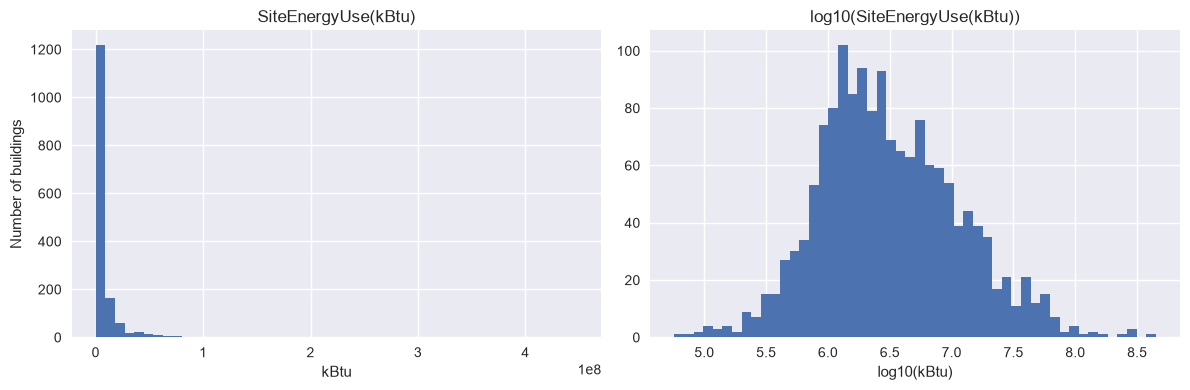

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y, bins=50)
axes[0].set_title(f"{TARGET}")
axes[0].set_xlabel("kBtu")
axes[0].set_ylabel("Number of buildings")

axes[1].hist(np.log10(y), bins=50)
axes[1].set_title(f"log10({TARGET})")
axes[1].set_xlabel("log10(kBtu)")

plt.tight_layout()
plt.show()

The mean is about 3 times the median, so the "average" building is not representative and the raw distribution is highly skewed.

We will be using log10(y) because the distribution becomes nearly symmetric and the model will minimize relative errors instead of chasing after the largest buildings.

**Important consequence:** if we train the model on log10(y), the predictions will need to be transformed back to kBtu, and the metrics computed in kBtu, so that they stay meaningful for the city.

In [26]:
threshold = y.quantile(0.9)
top_decile = y[y >= threshold]
print(
    f"The {len(top_decile)} biggest buildings (top 10%, >= {threshold:,.0f} kBtu) "
    f"account for {top_decile.sum() / y.sum():.1%} of the total energy use"
)

The 154 biggest buildings (top 10%, >= 17,808,998 kBtu) account for 57.9% of the total energy use


Energy use is highly concentrated: the 10% biggest buildings account for about 58% of the total. In volume, the city could cover most of the consumption by focusing on a small number of buildings. But these buildings mostly consume a lot because they are large, not necessarily because they waste energy: comparing buildings needs the energy use per square foot, which we look at below.

This concentration is another reason to model log10(y). On the raw scale, the errors on these few buildings would dominate a squared-error metric such as RMSE, and the model would mostly learn to fit them.

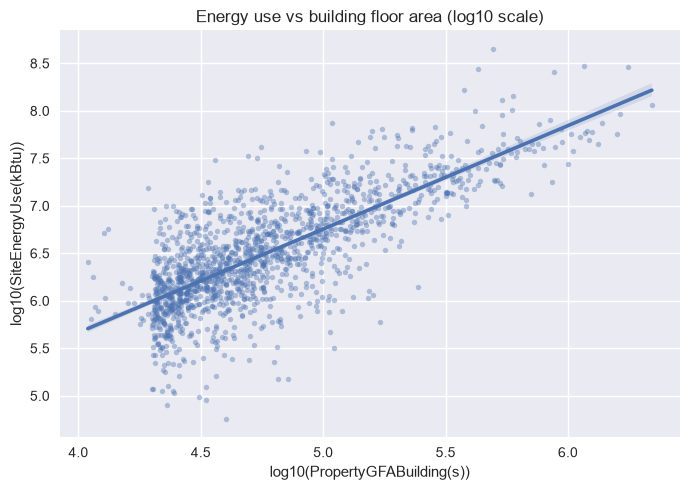

Spearman correlation: 0.72


In [27]:
AREA = "PropertyGFABuilding(s)"

log_data = pd.DataFrame(
    {
        f"log10({AREA})": np.log10(df[AREA]),
        f"log10({TARGET})": np.log10(df[TARGET]),
    }
)

fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(
    data=log_data,
    x=log_data.columns[0],
    y=log_data.columns[1],
    scatter_kws={"s": 15, "alpha": 0.4},
    ax=ax,
)
ax.set_title("Energy use vs building floor area (log10 scale)")
plt.tight_layout()
plt.show()

print(
    f"Spearman correlation: {log_data[log_data.columns[0]].corr(log_data[log_data.columns[1]], method='spearman'):.2f}"
)

Energy use grows with building area, roughly along a straight line on log10 scales, but with a large spread: at equal area, consumption can vary a lot. Area is the main driver, but not the only one.

The sharp left edge around log10(area) ≈ 4.3 (about 20,000 sq ft) is the threshold of Seattle’s benchmarking program, which only applies to buildings over 20,000 sq ft excluding parking ([source](https://www.seattle.gov/environment/climate-change/buildings-and-energy/energy-benchmarking/)). It is a data collection rule, not a property of the buildings: the model will not be valid for smaller buildings.

### Energy use intensity by building type

Boxes show the quartiles and the whiskers 1.5 times the interquartile range.

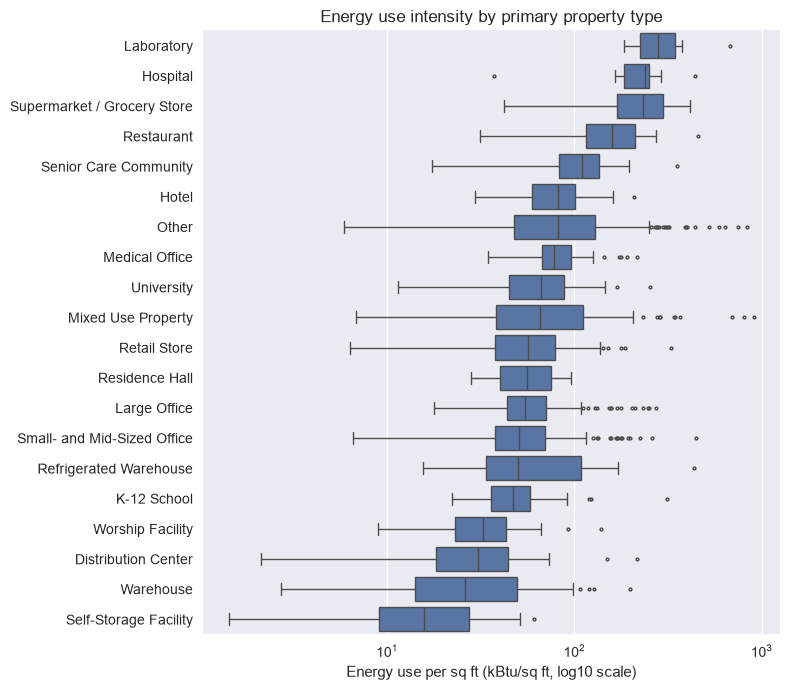

In [28]:
# Energy use intensity: energy use per square foot of building area (parking excluded)
intensity = df[TARGET] / df["PropertyGFABuilding(s)"]

order = (
    intensity.groupby(df["PrimaryPropertyType"]).median().sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 7))
sns.boxplot(
    x=intensity,
    y=df["PrimaryPropertyType"],
    order=order.index,
    fliersize=2,
    ax=ax,
)
ax.set_xscale("log")
ax.set_xlabel("Energy use per sq ft (kBtu/sq ft, log10 scale)")
ax.set_ylabel("")
ax.set_title("Energy use intensity by primary property type")
plt.tight_layout()
plt.show()

The most energy-intensive types are laboratories, hospitals, supermarkets and restaurants (median of about 160 to 280 kBtu per sq ft), while warehouses, distribution centers and self-storage facilities use the least (about 16 to 31 kBtu per sq ft). Laboratories and hospitals have only 10 buildings each (12 for restaurants), so their boxes are less reliable.

The boxes of different types are clearly shifted from one another, so the building type carries real information about the energy use per sq ft. But the boxes are also wide and overlap a lot, especially for the large, heterogeneous categories (`Other`, `Mixed Use Property`). The type is therefore a useful feature, but not sufficient alone.

### Energy use intensity by construction year

Each point is a building. The line shows the median per decade.

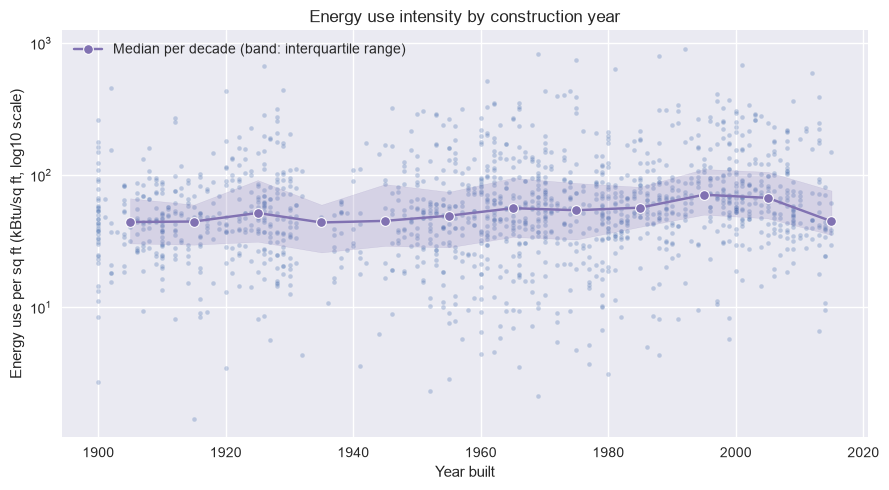

Spearman correlation: 0.19


In [29]:
year_eui = pd.DataFrame(
    {
        "YearBuilt": df["YearBuilt"],
        "decade": df["YearBuilt"] // 10 * 10 + 5,  # center of the decade
        "eui": intensity,
    }
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=year_eui, x="YearBuilt", y="eui", s=12, alpha=0.3, ax=ax)
sns.lineplot(
    data=year_eui,
    x="decade",
    y="eui",
    estimator="median",
    errorbar=("pi", 50),
    color="C3",
    marker="o",
    label="Median per decade (band: interquartile range)",
    ax=ax,
)
ax.set_yscale("log")
ax.set_xlabel("Year built")
ax.set_ylabel("Energy use per sq ft (kBtu/sq ft, log10 scale)")
ax.set_title("Energy use intensity by construction year")
plt.tight_layout()
plt.show()

print(
    f"Spearman correlation: {year_eui['YearBuilt'].corr(year_eui['eui'], method='spearman'):.2f}"
)

There is only a weak trend: the median stays between about 44 and 71 kBtu per sq ft from one decade to the next, and the rank correlation is only 0.19. Buildings from the 1960s to the 2000s are somewhat more intensive (about 54 to 71) than older ones (about 44 to 52), while the most recent decade goes back to about 45. The spread within each decade is much larger than the differences between decades. The construction year is therefore a weak feature on its own. It may still help in interaction with the building type, or as a construction period feature.

### Summary

Energy use is highly concentrated: the 10% biggest buildings account for about 58% of the total, and the mean is three times the median. Floor area is the primary driver (a roughly linear relationship on log10 scales, with a rank correlation of about 0.72), followed by the type of use, which shifts the energy use per sq ft but leaves a wide spread within each type. Because the raw target is strongly right-skewed (skewness 10.65), we model log10(y), which brings the skewness down to 0.35, and we convert predictions back to kBtu to compute the metrics.

The construction year has only a weak link with the energy use per sq ft. Finally, the data only covers buildings over 20,000 sq ft, so the model will not be valid for smaller ones.